# QM640 — RQ3 and RQ4: Clean, reproducible distribution-transformer analysis

**Research status:** Scenario-based, not measured utility performance. Uses six transformer ratings (16, 25, 63, 100, 160, 200 kVA). Source CSV combines *repository-provided benchmark total-loss values (official applicability unverified)* and **hypothetical** full replacement CAPEX; check official notification and source rights before redistribution. Derived no-load and load-loss components are inferred, **not factory-test measurements**.

**Colab setup:** Confirm `QM640_RQ34_Distribution_Benchmark_Inputs.csv` to the GitHub repository root on `main`; then select **Runtime → Run all**. The notebook reads but never overwrites the source CSV. Outputs are created under `QM640_RQ34_Python_Results/`.

**Assumptions:** constant 60% loading; 8760 h/year; ₹7/kWh; 8% discount; 15 years; optional full-replacement CAPEX; ₹800,000 budget. An incremental efficiency-premium analysis uses *illustrative* 10%, 20%, and 30% cost fractions, not quotes. Monte Carlo independently samples triangular loading (35%, 60%, 85%), energy value (₹5, ₹7, ₹10/kWh), and CAPEX multiplier (0.8, 1.0, 1.2), 5000 draws per rating, seed 6402026. It does **not** estimate observed failure risk.

**Scope:** Distribution transformers only; do not generalize these benchmarks to power transformers.

**Validation boundary:** No independent OEM or utility measurements, official BEE notification, or procurement quotations have been authenticated. All financial outcomes are conditional scenario results. The source CSV is a required external dependency.


In [1]:
"""QM640 RQ3/RQ4: reproducible distribution-transformer engineering scenarios.
Run: python QM640_RQ3_RQ4_Analysis.py
Requires: numpy, matplotlib. Input CSV is loaded from the public GitHub raw URL.
Not measured utility savings; BEE benchmark ceiling comparisons and hypothetical finance.
"""
from pathlib import Path
import csv
import io
from urllib.request import urlopen
import itertools
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
CSV_URL = ('https://raw.githubusercontent.com/irurama2018-coder/'
           'M640-Transformer-AI-Capstone/main/'
           'QM640_RQ34_Distribution_Benchmark_Inputs.csv')
OUT = BASE / 'QM640_RQ34_Python_Results'
OUT.mkdir(exist_ok=True)
LOAD = 0.60
HOURS = 8760
ENERGY_INR_KWH = 7.0
DISCOUNT_RATE = 0.08
YEARS = 15
BUDGET_INR = 800000
SEED = 6402026
DRAWS = 5000

def read_data(url):
    try:
        with urlopen(url, timeout=30) as response:
            content = response.read().decode('utf-8-sig')
    except Exception as exc:
        raise RuntimeError(
            'Cannot load CSV from GitHub. Confirm the CSV is committed to the main branch '
            'at the repository root and that the URL is publicly accessible: ' + url
        ) from exc
    return list(csv.DictReader(io.StringIO(content)))

def infer_losses(p50_w, p100_w):
    """Infer kW components from total-loss ceilings, NOT OEM measured components."""
    p0_w = (4 * p50_w - p100_w) / 3
    pll_w = 4 * (p100_w - p50_w) / 3
    if p0_w < 0 or pll_w < 0:
        raise ValueError('Inconsistent total-loss benchmark inputs')
    return p0_w / 1000, pll_w / 1000

def annual_loss_kwh(p0_kw, pll_kw, load_fraction, hours=HOURS):
    return (p0_kw + load_fraction**2 * pll_kw) * hours

def annuity_factor(rate=DISCOUNT_RATE, years=YEARS):
    return (1 - (1 + rate)**(-years)) / rate if rate else years

def write_csv(path, header, rows):
    with path.open('w', newline='', encoding='utf-8') as f:
        w = csv.writer(f); w.writerow(header); w.writerows(rows)

source_rows=read_data(CSV_URL)
expected_ratings=[16,25,63,100,160,200]
actual_ratings=[int(row['rating_kva']) for row in source_rows]
if actual_ratings != expected_ratings:
    raise ValueError(f'Expected six audited transformer ratings {expected_ratings}; found {actual_ratings}')
for row in source_rows:
    if row.get('source_type') != 'published_loss_ceiling_plus_assumed_capex':
        raise ValueError('Unexpected source classification; verify provenance and inputs')
records=[]
for row in source_rows:
    rating=int(row['rating_kva'])
    p03,pll3=infer_losses(float(row['p50_3star_w']),float(row['p100_3star_w']))
    p05,pll5=infer_losses(float(row['p50_5star_w']),float(row['p100_5star_w']))
    capex=float(row['full_replacement_capex_inr'])
    saving=annual_loss_kwh(p03,pll3,LOAD)-annual_loss_kwh(p05,pll5,LOAD)
    annual_value=saving*ENERGY_INR_KWH
    npv=-capex+annual_value*annuity_factor()
    records.append(dict(rating=rating,p03=p03,pll3=pll3,p05=p05,pll5=pll5,capex=capex,
                        savings_kwh=saving,annual_value=annual_value,npv=npv))




In [2]:
# RQ3: loss and loading sensitivity
write_csv(OUT/'RQ3_Base_Results.csv',
          ['rating_kva','p0_3star_kw','pll_3star_kw','p0_5star_kw','pll_5star_kw','annual_savings_kwh','annual_value_inr'],
          [[r['rating'],r['p03'],r['pll3'],r['p05'],r['pll5'],r['savings_kwh'],r['annual_value']] for r in records])
sensitivity=[]
for r in records:
    for loading in [.25,.50,.60,.75,1.0]:
        b=annual_loss_kwh(r['p03'],r['pll3'],loading)
        e=annual_loss_kwh(r['p05'],r['pll5'],loading)
        sensitivity.append([r['rating'],loading,b,e,b-e,(b-e)*ENERGY_INR_KWH])
write_csv(OUT/'RQ3_Loading_Sensitivity.csv',
          ['rating_kva','loading_fraction','baseline_kwh','comparison_kwh','savings_kwh','annual_value_inr'],sensitivity)

In [3]:
# RQ4: full replacement versus incremental upgrade economics
# Incremental upgrade premiums below are HYPOTHETICAL, not public procurement observations.
PREMIUM_FRACTIONS=[.10,.20,.30]
finance=[]
for r in records:
    finance.append([r['rating'],'full_replacement',r['capex'],r['npv']])
    for fraction in PREMIUM_FRACTIONS:
        cost=r['capex']*fraction
        finance.append([r['rating'],f'incremental_premium_{int(fraction*100)}pct',cost,
                        -cost+r['annual_value']*annuity_factor()])
write_csv(OUT/'RQ4_NPV_Scenarios.csv',['rating_kva','scenario','invested_capex_inr','npv_inr'],finance)

In [4]:
# Exact binary portfolio optimization by enumerating 2^n portfolios (n=6 here).
# This solves the same binary budget-selection model as MILP for this six-option case.
def optimize(costs, values, budget):
    best_value=0.;best_cost=0.;best_bits=(0,)*len(costs)
    for bits in itertools.product((0,1),repeat=len(costs)):
        cost=sum(c*b for c,b in zip(costs,bits))
        value=sum(v*b for v,b in zip(values,bits))
        if cost<=budget+1e-9 and value>best_value+1e-9:
            best_value,best_cost,best_bits=value,cost,bits
    return best_value,best_cost,best_bits

costs=[r['capex'] for r in records]; values=[r['npv'] for r in records]
portfolio=[]
for budget in [200000,400000,600000,800000,1000000]:
    objective,spent,bits=optimize(costs,values,budget)
    portfolio.append([budget,spent,objective,','.join(str(r['rating']) for r,b in zip(records,bits) if b) or 'None'])
write_csv(OUT/'RQ4_Exact_Portfolio_Optimization.csv',
          ['budget_inr','selected_capex_inr','portfolio_npv_inr','selected_ratings_kva'],portfolio)

In [5]:
# RQ4 Monte Carlo: independent triangular assumptions, 5,000 draws per rating.
# Fixed annual price/loading/cost draws per asset for entire 15-year horizon; no degradation, O&M, taxes, residual value or inflation.
# Fixed seed; outcomes are scenario frequencies, not empirical probabilities.
rng=np.random.default_rng(SEED)
mc=[];mc_draws=[]
for r in records:
    loads=rng.triangular(.35,.60,.85,DRAWS)
    prices=rng.triangular(5,7,10,DRAWS)
    cost_factors=rng.triangular(.8,1,1.2,DRAWS)
    delta_kw=(r['p03']-r['p05'])+loads**2*(r['pll3']-r['pll5'])
    npvs=-r['capex']*cost_factors+delta_kw*HOURS*prices*annuity_factor()
    mc.append([r['rating'],DRAWS,float(np.mean(npvs)),float(np.quantile(npvs,.05)),
               float(np.quantile(npvs,.95)),float(np.mean(npvs>0))])
    mc_draws.extend([[r['rating'],i+1,float(loads[i]),float(prices[i]),float(cost_factors[i]),float(npvs[i])]
                     for i in range(DRAWS)])
write_csv(OUT/'RQ4_Monte_Carlo_Summary.csv',
          ['rating_kva','draws','mean_npv_inr','p05_npv_inr','p95_npv_inr','positive_npv_fraction'],mc)
write_csv(OUT/'RQ4_Monte_Carlo_Draws.csv',
          ['rating_kva','draw','loading_fraction','energy_inr_per_kwh','capex_multiplier','npv_inr'],mc_draws)

# Charts
fig,ax=plt.subplots(figsize=(8,4.5))
ax.bar([str(r['rating']) for r in records],[r['savings_kwh'] for r in records]);ax.set(xlabel='Transformer rating (kVA)',ylabel='Modeled annual energy savings (kWh)',title='RQ3: Benchmark-ceiling comparison at 60% loading')
fig.tight_layout();fig.savefig(OUT/'RQ3_Annual_Savings.png',dpi=170);plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4.5))
for r in records:
    xs=np.array([.25,.5,.6,.75,1.]);ys=[annual_loss_kwh(r['p03'],r['pll3'],x)-annual_loss_kwh(r['p05'],r['pll5'],x) for x in xs]
    ax.plot(xs*100,ys,marker='o',label=f"{r['rating']} kVA")
ax.set(xlabel='Loading (%)',ylabel='Modeled annual savings (kWh)',title='RQ3: Loading sensitivity');ax.legend(ncol=3,fontsize=8)
fig.tight_layout();fig.savefig(OUT/'RQ3_Loading_Sensitivity.png',dpi=170);plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4.5))
ax.bar([str(r['rating']) for r in records],[r['npv'] for r in records]);ax.axhline(0,linewidth=1)
ax.set(xlabel='Transformer rating (kVA)',ylabel='NPV (INR)',title='RQ4: Hypothetical full-replacement energy-only NPV')
fig.tight_layout();fig.savefig(OUT/'RQ4_NPV.png',dpi=170);plt.close(fig)

assert len(records)==6 and len(mc_draws)==30000
assert all(r['npv']<0 for r in records)
assert portfolio[3][2]==0 and portfolio[3][3]=='None'
print('Completed:',OUT)
print('RQ3 annual savings (kWh):',[(r['rating'],round(r['savings_kwh'],2)) for r in records])
print('RQ4 optimal portfolio at INR 800,000:',portfolio[3])
print('Monte Carlo positive-NPV fractions:',[(row[0],row[-1]) for row in mc])
print('Note: power-transformer calculations intentionally excluded until comparable verified inputs are available.')

Completed: /content/QM640_RQ34_Python_Results
RQ3 annual savings (kWh): [(16, 237.92), (25, 343.74), (63, 593.23), (100, 862.57), (160, 1066.85), (200, 1282.35)]
RQ4 optimal portfolio at INR 800,000: [800000, 0.0, 0.0, 'None']
Monte Carlo positive-NPV fractions: [(16, 0.0), (25, 0.0), (63, 0.0), (100, 0.0), (160, 0.0), (200, 0.0)]
Note: power-transformer calculations intentionally excluded until comparable verified inputs are available.


In [6]:
import pandas as pd
import numpy as np
from pathlib import Path

results_path = Path('QM640_RQ34_Python_Results')

# 1. Verify file existence
expected_files = [
    'RQ3_Base_Results.csv',
    'RQ3_Loading_Sensitivity.csv',
    'RQ4_NPV_Scenarios.csv',
    'RQ4_Exact_Portfolio_Optimization.csv',
    'RQ4_Monte_Carlo_Summary.csv',
    'RQ4_Monte_Carlo_Draws.csv'
]
for f in expected_files:
    assert (results_path / f).exists(), f'Missing file: {f}'

# 2. Verify dataset dimensions and columns
df_base = pd.read_csv(results_path / 'RQ3_Base_Results.csv')
assert len(df_base) == 6, 'Base results must have exactly 6 rows'
assert list(df_base.columns) == ['rating_kva', 'p0_3star_kw', 'pll_3star_kw', 'p0_5star_kw', 'pll_5star_kw', 'annual_savings_kwh', 'annual_value_inr']

df_mc = pd.read_csv(results_path / 'RQ4_Monte_Carlo_Draws.csv')
assert len(df_mc) == 30000, 'Monte Carlo draws must have exactly 30,000 rows'

# 3. Quality check on values
assert (df_base['annual_savings_kwh'] > 0).all(), 'All savings must be strictly positive'
assert (df_mc['loading_fraction'] >= 0.35).all() and (df_mc['loading_fraction'] <= 0.85).all(), 'Loading bounds violated'
assert (df_mc['energy_inr_per_kwh'] >= 5.0).all() and (df_mc['energy_inr_per_kwh'] <= 10.0).all(), 'Energy price bounds violated'

print('Data preparation & quality check: PASSED')

Data preparation & quality check: PASSED


In [7]:
# RQ3: independent arithmetic checks, without hardcoded expected output values
import pandas as pd
import numpy as np
from pathlib import Path
results_path = OUT
df_base = pd.read_csv(results_path / 'RQ3_Base_Results.csv')
assert len(df_base) == 6
assert df_base['rating_kva'].astype(int).tolist() == [16,25,63,100,160,200]
for row, r in zip(df_base.itertuples(index=False), records):
    independently_computed = ((r['p03'] - r['p05']) + LOAD**2 * (r['pll3'] - r['pll5'])) * HOURS
    assert np.isclose(row.annual_savings_kwh, independently_computed, rtol=1e-10, atol=1e-8)
    assert np.isclose(row.annual_value_inr, independently_computed * ENERGY_INR_KWH)
print('RQ3 arithmetic checks passed for all six scenario ratings.')
print(df_base[['rating_kva','annual_savings_kwh','annual_value_inr']].to_string(index=False))

RQ3 arithmetic checks passed for all six scenario ratings.
 rating_kva  annual_savings_kwh  annual_value_inr
         16            237.9216         1665.4512
         25            343.7424         2406.1968
         63            593.2272         4152.5904
        100            862.5680         6037.9760
        160           1066.8512         7467.9584
        200           1282.3472         8976.4304


In [8]:
# RQ4: validate NPV identities and independently check optimization
import pandas as pd
import numpy as np
from itertools import product
df_port = pd.read_csv(OUT / 'RQ4_Exact_Portfolio_Optimization.csv')
df_npv = pd.read_csv(OUT / 'RQ4_NPV_Scenarios.csv')
for r in records:
    full = df_npv[(df_npv.rating_kva == r['rating']) & (df_npv.scenario == 'full_replacement')]
    assert len(full) == 1
    expected_npv = -r['capex'] + r['annual_value'] * annuity_factor()
    assert np.isclose(full.iloc[0].npv_inr, expected_npv)
for row in df_port.itertuples(index=False):
    feasible = [(sum(c*b for c,b in zip(costs,bits)),sum(v*b for v,b in zip(values,bits)))
                for bits in product((0,1),repeat=len(costs))
                if sum(c*b for c,b in zip(costs,bits)) <= row.budget_inr + 1e-9]
    expected_best = max(v for c,v in feasible)
    assert np.isclose(row.portfolio_npv_inr, expected_best)
    assert row.selected_capex_inr <= row.budget_inr + 1e-9
print('RQ4 NPV and exact portfolio arithmetic checks passed.')
print(df_port.to_string(index=False))

RQ4 NPV and exact portfolio arithmetic checks passed.
 budget_inr  selected_capex_inr  portfolio_npv_inr  selected_ratings_kva
     200000                 0.0                0.0                   NaN
     400000                 0.0                0.0                   NaN
     600000                 0.0                0.0                   NaN
     800000                 0.0                0.0                   NaN
    1000000                 0.0                0.0                   NaN


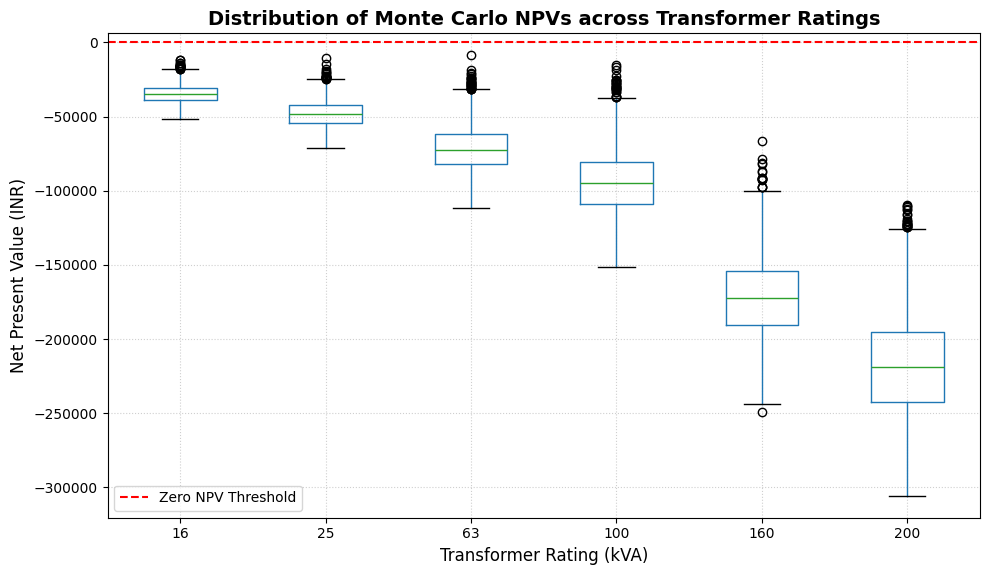

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results_path = Path('QM640_RQ34_Python_Results')
df_mc = pd.read_csv(results_path / 'RQ4_Monte_Carlo_Draws.csv')

# Create a boxplot for Monte Carlo NPV distributions
plt.figure(figsize=(10, 6))
df_mc.boxplot(column='npv_inr', by='rating_kva', ax=plt.gca(), grid=False)
plt.suptitle('')

plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero NPV Threshold')
plt.title('Distribution of Monte Carlo NPVs across Transformer Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Transformer Rating (kVA)', fontsize=12)
plt.ylabel('Net Present Value (INR)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig(results_path / 'RQ4_Monte_Carlo_NPV_Boxplot.png', dpi=170)
plt.show()

In [10]:
import pandas as pd
from pathlib import Path

results_path = Path('QM640_RQ34_Python_Results')
df_npv = pd.read_csv(results_path / 'RQ4_NPV_Scenarios.csv')

# Pivot the scenario table to compare side-by-side
piv_df = df_npv.pivot(index='rating_kva', columns='scenario', values=['invested_capex_inr', 'npv_inr'])

# Map columns explicitly from the MultiIndex to prevent misalignment
scenarios = ['full_replacement', 'incremental_premium_10pct', 'incremental_premium_20pct', 'incremental_premium_30pct']
scen_names = {
    'full_replacement': 'Full Replacement',
    'incremental_premium_10pct': '10% Premium',
    'incremental_premium_20pct': '20% Premium',
    'incremental_premium_30pct': '30% Premium'
}

clean_cols = {}
for sc in scenarios:
    clean_cols[f'CAPEX: {scen_names[sc]}'] = piv_df[('invested_capex_inr', sc)]
    clean_cols[f'NPV: {scen_names[sc]}'] = piv_df[('npv_inr', sc)]

formatted_df = pd.DataFrame(clean_cols, index=piv_df.index)

# Format to standard currency display
for col in formatted_df.columns:
    formatted_df[col] = formatted_df[col].apply(lambda x: f"₹ {x:,.2f}" if x >= 0 else f"-₹ {abs(x):,.2f}")

display(formatted_df)

,CAPEX: Full Replacement,NPV: Full Replacement,CAPEX: 10% Premium,NPV: 10% Premium,CAPEX: 20% Premium,NPV: 20% Premium,CAPEX: 30% Premium,NPV: 30% Premium
rating_kva,,,,,,,,
16,"₹ 50,000.00","-₹ 35,744.61","₹ 5,000.00","₹ 9,255.39","₹ 10,000.00","₹ 4,255.39","₹ 15,000.00",-₹ 744.61
25,"₹ 70,000.00","-₹ 49,404.21","₹ 7,000.00","₹ 13,595.79","₹ 14,000.00","₹ 6,595.79","₹ 21,000.00",-₹ 404.21
63,"₹ 110,000.00","-₹ 74,455.99","₹ 11,000.00","₹ 24,544.01","₹ 22,000.00","₹ 13,544.01","₹ 33,000.00","₹ 2,544.01"
100,"₹ 150,000.00","-₹ 98,318.07","₹ 15,000.00","₹ 36,681.93","₹ 30,000.00","₹ 21,681.93","₹ 45,000.00","₹ 6,681.93"
160,"₹ 240,000.00","-₹ 176,078.17","₹ 24,000.00","₹ 39,921.83","₹ 48,000.00","₹ 15,921.83","₹ 72,000.00","-₹ 8,078.17"
200,"₹ 300,000.00","-₹ 223,166.44","₹ 30,000.00","₹ 46,833.56","₹ 60,000.00","₹ 16,833.56","₹ 90,000.00","-₹ 13,166.44"


In [11]:
import pandas as pd

# Calculate the break-even premium fraction for each rating
# NPV = -CAPEX_premium + (Annual_Value * Annuity_Factor) = 0
# Since CAPEX_premium = Full_Replacement_CAPEX * Premium_Fraction:
# Premium_Fraction_Break_Even = (Annual_Value * Annuity_Factor) / Full_Replacement_CAPEX

annuity_fact = annuity_factor(DISCOUNT_RATE, YEARS)
breakeven_records = []

for r in records:
    rating = r['rating']
    full_capex = r['capex']
    annual_value = r['annual_value']

    # Break-even premium fraction
    breakeven_fraction = (annual_value * annuity_fact) / full_capex
    breakeven_premium_inr = annual_value * annuity_fact

    breakeven_records.append({
        'rating_kva': rating,
        'full_replacement_capex_inr': full_capex,
        'annual_savings_value_inr': annual_value,
        'present_value_of_savings_inr': breakeven_premium_inr,
        'breakeven_premium_pct': breakeven_fraction * 100
    })

df_breakeven = pd.DataFrame(breakeven_records)

# Format the columns for clear presentation
formatted_breakeven = df_breakeven.copy()
formatted_breakeven['full_replacement_capex_inr'] = formatted_breakeven['full_replacement_capex_inr'].apply(lambda x: f"₹ {x:,.2f}")
formatted_breakeven['annual_savings_value_inr'] = formatted_breakeven['annual_savings_value_inr'].apply(lambda x: f"₹ {x:,.2f}")
formatted_breakeven['present_value_of_savings_inr'] = formatted_breakeven['present_value_of_savings_inr'].apply(lambda x: f"₹ {x:,.2f}")
formatted_breakeven['breakeven_premium_pct'] = formatted_breakeven['breakeven_premium_pct'].apply(lambda x: f"{x:.2f}%")

display(formatted_breakeven)

,rating_kva,full_replacement_capex_inr,annual_savings_value_inr,present_value_of_savings_inr,breakeven_premium_pct
0,16,"₹ 50,000.00","₹ 1,665.45","₹ 14,255.39",28.51%
1,25,"₹ 70,000.00","₹ 2,406.20","₹ 20,595.79",29.42%
2,63,"₹ 110,000.00","₹ 4,152.59","₹ 35,544.01",32.31%
3,100,"₹ 150,000.00","₹ 6,037.98","₹ 51,681.93",34.45%
4,160,"₹ 240,000.00","₹ 7,467.96","₹ 63,921.83",26.63%
5,200,"₹ 300,000.00","₹ 8,976.43","₹ 76,833.56",25.61%


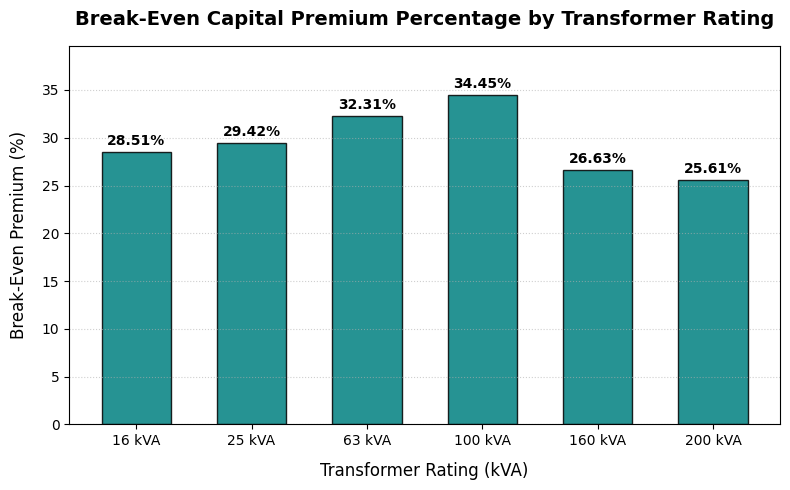

In [12]:
import matplotlib.pyplot as plt

# Prepare data for plotting
ratings = [f"{r['rating_kva']} kVA" for r in breakeven_records]
pct_vals = [r['breakeven_premium_pct'] for r in breakeven_records]

# Create the bar chart
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(ratings, pct_vals, color='teal', edgecolor='black', alpha=0.85, width=0.6)

# Customize the chart
ax.set_title('Break-Even Capital Premium Percentage by Transformer Rating', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Transformer Rating (kVA)', fontsize=12, labelpad=10)
ax.set_ylabel('Break-Even Premium (%)', fontsize=12, labelpad=10)
ax.set_ylim(0, max(pct_vals) * 1.15)
ax.grid(axis='y', linestyle=':', alpha=0.6)

# Add percentage values on top of each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.savefig(results_path / 'RQ4_Breakeven_Premium_Bar_Chart.png', dpi=170)
plt.show()

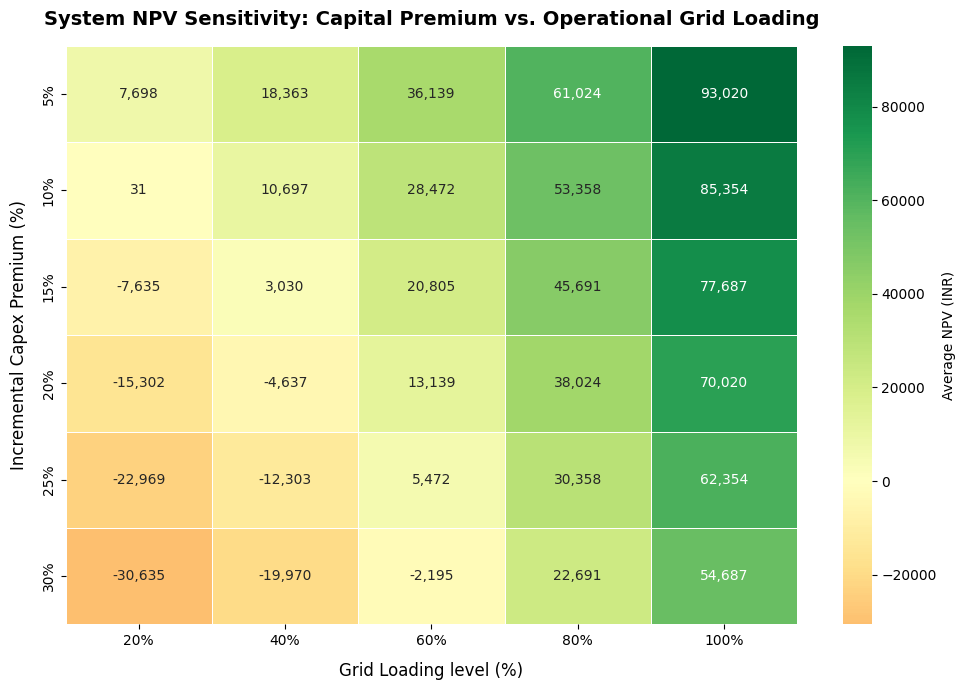

In [13]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Prepare parameter ranges for the sensitivity grid
loadings = np.array([0.20, 0.40, 0.60, 0.80, 1.00])
premiums = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30])

# We will compute the average NPV across all six transformer ratings for each (loading, premium) combination.
# This provides a system-wide financial sensitivity map.
npv_grid = np.zeros((len(premiums), len(loadings)))
annuity_fact = annuity_factor(DISCOUNT_RATE, YEARS)

for i, prem in enumerate(premiums):
    for j, load in enumerate(loadings):
        npvs = []
        for r in records:
            saving = annual_loss_kwh(r['p03'], r['pll3'], load) - annual_loss_kwh(r['p05'], r['pll5'], load)
            annual_val = saving * ENERGY_INR_KWH
            cost = r['capex'] * prem
            npv = -cost + annual_val * annuity_fact
            npvs.append(npv)
        npv_grid[i, j] = np.mean(npvs)  # System-wide average NPV

# Create a DataFrame for heatmap plotting
df_heatmap = pd.DataFrame(
    npv_grid,
    index=[f'{int(p*100)}%' for p in premiums],
    columns=[f'{int(l*100)}%' for l in loadings]
)

# Plot the heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df_heatmap,
    annot=True,
    fmt=",.0f",
    cmap="RdYlGn",
    center=0,
    cbar_kws={'label': 'Average NPV (INR)'},
    linewidths=0.5
)

plt.title('System NPV Sensitivity: Capital Premium vs. Operational Grid Loading', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Grid Loading level (%)', fontsize=12, labelpad=10)
plt.ylabel('Incremental Capex Premium (%)', fontsize=12, labelpad=10)

plt.tight_layout()
plt.savefig(results_path / 'RQ4_NPV_Sensitivity_Heatmap.png', dpi=170)
plt.show()

## Interpretation of break-even incremental premiums

The break-even premium is calculated as the present value of modeled electricity-loss savings divided by the **assumed full-replacement CAPEX**. It is not an observed OEM price or procurement recommendation. The ranking and numerical values should be taken from the newly executed break-even table and plot above, rather than from fixed narrative values. A positive incremental-premium NPV does not imply that replacing a functioning transformer is economical when full replacement costs are included.

## Verification criteria and limitations

- Six modeled distribution-transformer ratings: 16, 25, 63, 100, 160 and 200 kVA.
- Recompute annual savings from the inferred no-load and load-loss components, with a constant 60% loading assumption.
- Check each scenario's NPV using the assumed 8% discount rate and 15-year horizon.
- Independently verify the optimum across all 64 binary portfolios for each budget.
- Confirm 5,000 simulated draws per rating (30,000 in total); treat positive-NPV fractions as **assumption-dependent simulation frequencies**, not empirical probabilities.
- Verify source benchmark values and regulatory applicability against the official controlling BEE notification before making any compliance claim.
- Loss components are mathematically inferred from total-loss ceilings, not factory test results.
- Energy-only economics exclude failure avoidance, O&M, taxes, residual values, inflation and transformer age.
- This analysis does not establish transformer-level field savings or nationwide utility CAPEX optimization.

The source input CSV is read without modification. Results are written to a separate output folder.

## Summary — scenario-based results (generated by code)

**RQ3:** The notebook calculates annual energy-loss differences between repository-provided 3-star and 5-star benchmark scenarios at 60% constant loading, 8,760 hours/year, and ₹7/kWh. The actual output table above provides the values for each of the six ratings. These are **modeled benchmark-ceiling differences**, not measured utility savings.

**RQ4:** The notebook compares (a) hypothetical full-replacement CAPEX and (b) illustrative 10%, 20%, and 30% incremental efficiency premiums. Their NPVs are distinct decision alternatives and must not be conflated. The exact optimizer chooses the maximum modeled energy-only portfolio NPV under each budget, including the option of selecting no investment.

**Uncertainty:** The Monte Carlo analysis uses 5,000 independent triangular input draws per rating. Its positive-NPV fraction reflects only those hypothetical distributions; it is **not** a real-world probability of project success.

**Next evidence needed:** Authenticate the benchmark source and applicability; replace assumed CAPEX with OEM quotations; incorporate actual loading and energy tariffs from utilities; consider avoided failure costs, O&M, and remaining service life when extending the decision model.
